In [1]:
! pip install --upgrade xarray zarr gcsfs cftime nc-time-axis

In [2]:
import numpy as np
import pandas as pd
import xarray as xr
import gcsfs
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = 12, 6
gcs = gcsfs.GCSFileSystem(token="anon")

# catalog of every dataset in the google cloud cmip6 collection
catalog = pd.read_csv("https://storage.googleapis.com/cmip6/cmip6-zarr-consolidated-stores.csv")
catalog.head()

,activity_id,institution_id,source_id,experiment_id,member_id,table_id,variable_id,grid_label,zstore,dcpp_init_year,version
0,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,ps,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
1,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,rsds,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
2,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,rlus,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
3,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,rlds,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
4,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,psl,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706


In [3]:
# which experiments exist, looking for historical, ssp126, ssp245, ssp585
catalog.experiment_id.value_counts().head(20)

experiment_id
dcppA-hindcast     141016
historical          86693
ssp245              39097
ssp585              34643
ssp370              32739
ssp126              27676
abrupt-4xCO2        12694
1pctCO2             12042
piControl           10834
ssp119              10157
amip                 7949
pdSST-pdSIC          6275
pdSST-futArcSIC      5774
hist-GHG             5244
hist-nat             4981
esm-hist             4902
hist-aer             4208
ssp534-over          3530
pdSST-piArcSIC       3253
ssp434               3223
Name: count, dtype: int64

In [4]:
# which monthly variables exist, looking for tas (air temperature) and pr (precipitation)
catalog.query("table_id == 'Amon'").variable_id.value_counts().head(20)

variable_id
tas        15492
psl        12938
clt        11467
ps         11378
evspsbl    11080
ts         10537
rsdt        8365
huss        8108
rsds        7460
rlut        7409
hus         7306
ta          7230
ua          7176
va          7172
hfls        7120
zg          7033
pr          6861
hfss        6850
rsus        6770
tasmax      6699
Name: count, dtype: int64

In [5]:
# which models have monthly temperature for the high emissions scenario
catalog.query("variable_id == 'tas' & table_id == 'Amon' & experiment_id == 'ssp585'").source_id.unique()

array(['GFDL-CM4', 'GFDL-ESM4', 'CNRM-CM6-1', 'BCC-CSM2-MR',
       'CNRM-ESM2-1', 'CanESM5', 'CanESM5-CanOE', 'UKESM1-0-LL',
       'AWI-CM-1-1-MR', 'INM-CM4-8', 'MIROC6', 'CAMS-CSM1-0',
       'MPI-ESM1-2-LR', 'MPI-ESM1-2-HR', 'INM-CM5-0', 'NESM3',
       'MCM-UA-1-0', 'FGOALS-g3', 'MIROC-ES2L', 'IPSL-CM6A-LR',
       'KACE-1-0-G', 'FGOALS-f3-L', 'MRI-ESM2-0', 'NorESM2-LM',
       'NorESM2-MM', 'CNRM-CM6-1-HR', 'FIO-ESM-2-0', 'HadGEM3-GC31-LL',
       'GISS-E2-1-G', 'GISS-E2-1-H', 'EC-Earth3-Veg', 'EC-Earth3',
       'CESM2-WACCM', 'ACCESS-CM2', 'HadGEM3-GC31-MM', 'CESM2', 'CIESM',
       'CMCC-CM2-SR5', 'TaiESM1', 'IITM-ESM', 'E3SM-1-1',
       'EC-Earth3-Veg-LR', 'CAS-ESM2-0', 'EC-Earth3-CC', 'CMCC-ESM2',
       'ACCESS-ESM1-5', 'KIOST-ESM'], dtype=object)

In [6]:
# gfdl-esm4 has historical plus all three future scenarios for this run
model = "GFDL-ESM4"
member = "r1i1p1f1"
names = {"ssp126": "low (SSP1-2.6)", "ssp245": "middle (SSP2-4.5)", "ssp585": "high (SSP5-8.5)"}

def load(var, exp):
    # use the newest version if there are several
    row = catalog.query(
        "table_id == 'Amon' & variable_id == @var & experiment_id == @exp "
        "& source_id == @model & member_id == @member"
    ).sort_values("version").iloc[-1]
    da = xr.open_zarr(gcs.get_mapper(row.zstore), consolidated=True)[var]
    # switch longitude from 0 to 360 into -180 to 180 so it lines up with normal maps
    return da.assign_coords(lon=((da.lon + 180) % 360) - 180).sortby("lon")

def yearly_global(da):
    # cells near the poles cover less area, so weight by cos(latitude)
    w = np.cos(np.deg2rad(da.lat))
    return da.weighted(w).mean(["lat", "lon"]).groupby("time.year").mean()

In [7]:
# global warming per year, measured against the 1850 to 1900 average
# this cell takes a few minutes since it downloads the data
hist = load("tas", "historical")
hist_g = yearly_global(hist).load()
base = hist_g.sel(year=slice(1850, 1900)).mean()

future = {}
future_g = {}
for s in names:
    future[s] = load("tas", s).sel(time=slice("2015", "2100"))
    future_g[s] = yearly_global(future[s]).load()

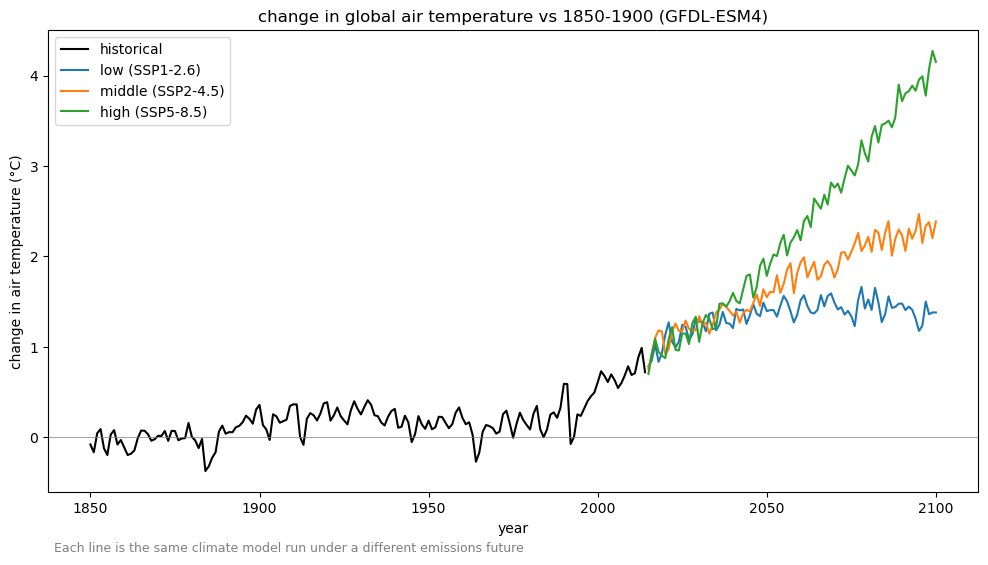

In [8]:
# plot 1: global warming under each scenario
(hist_g - base).plot(color="black", label="historical")
for s in names:
    (future_g[s] - base).plot(label=names[s])
plt.axhline(0, color="gray", lw=0.5)
plt.title(f"change in global air temperature vs 1850-1900 ({model})")
plt.ylabel("change in air temperature (°C)")
plt.figtext(0.13, 0.01, "Each line is the same climate model run under a different emissions future", fontsize=9, color="gray")
plt.legend()
plt.show()

In [9]:
# warming maps for each decade from the 2020s to the 2090s
# resampled to a 5 degree grid so it stays small and quick to work with
lat = np.arange(-87.5, 90, 5)
lon = np.arange(-177.5, 180, 5)
base_map = hist.sel(time=slice("1850", "1900")).mean("time").load().interp(lat=lat, lon=lon)

maps = {}
for s in names:
    yr = future[s].sel(time=slice("2020", "2099")).groupby("time.year").mean()
    dec = yr.groupby((yr.year // 10 * 10).rename("decade")).mean().load()
    maps[s] = dec.interp(lat=lat, lon=lon) - base_map

In [10]:
# plot 2 with a slider to step through decades
from ipywidgets import interact

def show(decade):
    maps["ssp585"].sel(decade=decade).plot(cmap="Reds", vmin=0, vmax=top, cbar_kwargs={"label": "change in air temperature (°C)"})
    plt.title(f"change in air temperature in the {decade}s, high emissions")
    plt.show()

top = float(maps["ssp585"].sel(decade=2090).max())
interact(show, decade=(2020, 2090, 10))

interactive(children=(IntSlider(value=2050, description='decade', max=2090, min=2020, step=10), Output()), _do…

<function __main__.show(decade)>

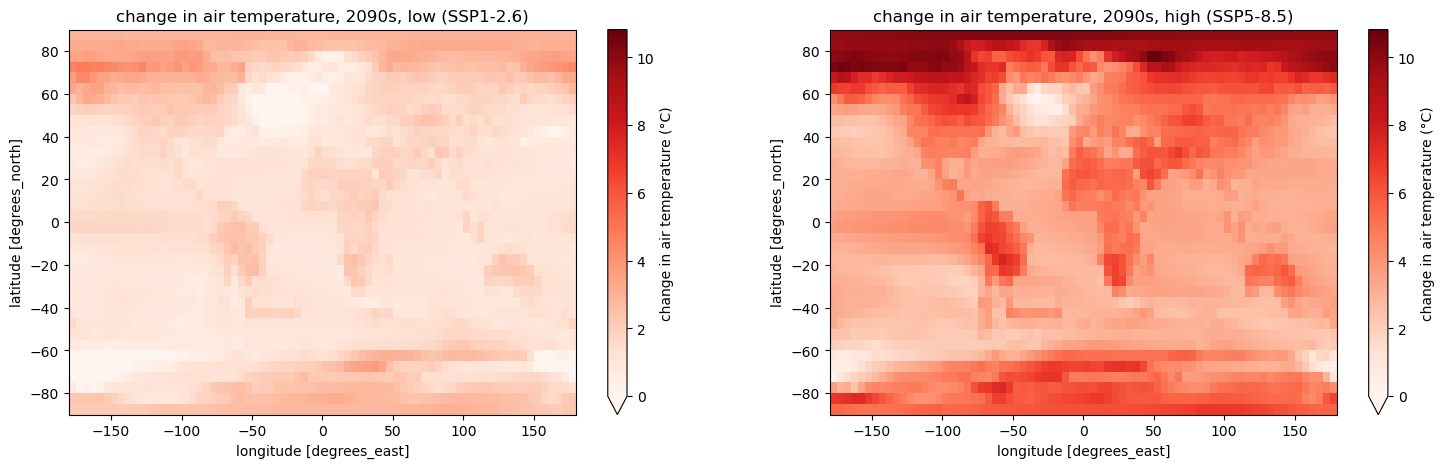

In [11]:
# plot 3: low vs high emissions side by side, same color scale
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
top = float(maps["ssp585"].sel(decade=2090).max())
for ax, s in zip(axes, ["ssp126", "ssp585"]):
    maps[s].sel(decade=2090).plot(ax=ax, cmap="Reds", vmin=0, vmax=top, cbar_kwargs={"label": "change in air temperature (°C)"})
    ax.set_title(f"change in air temperature, 2090s, {names[s]}")
plt.show()

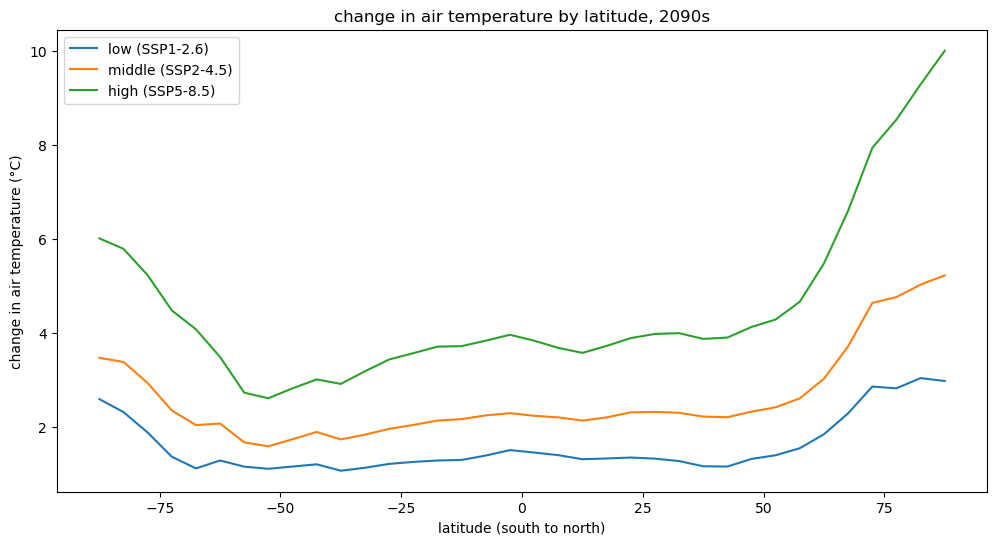

In [12]:
# plot 4: warming by latitude, to see if the poles warm faster
for s in names:
    z = maps[s].sel(decade=2090).mean("lon")
    plt.plot(z.lat, z, label=names[s])
plt.title("change in air temperature by latitude, 2090s")
plt.xlabel("latitude (south to north)")
plt.ylabel("change in air temperature (°C)")
plt.legend()
plt.show()

In [13]:
# plot 5: san diego compared to the global average, high emissions
# note: tas is stored in kelvin, but a change in kelvin equals a change in celsius,
# so the anomalies below are already in °C and need no conversion
# 10 year rolling average to smooth out the year to year noise
sd = dict(lat=32.7, lon=-117.2, method="nearest")
sd_hist = hist.sel(**sd).groupby("time.year").mean().load()
sd_base = sd_hist.sel(year=slice(1850, 1900)).mean()
sd_high = future["ssp585"].sel(**sd).groupby("time.year").mean().load()

sd_all = xr.concat([sd_hist, sd_high], dim="year") - sd_base
global_all = xr.concat([hist_g, future_g["ssp585"]], dim="year") - base

sd_all.rolling(year=10, center=True).mean().plot(label="san diego")
global_all.rolling(year=10, center=True).mean().plot(color="gray", label="global average")
plt.axvline(2015, color="gray", lw=0.5, ls="--")
plt.title("change in air temperature: san diego vs global average, high emissions")
plt.ylabel("change in air temperature (°C)")
plt.legend()
plt.show()

KeyboardInterrupt: 

In [ ]:
# plot 6: rainfall change by the 2090s under high emissions, as a percent
# brown is drier, green is wetter
pr_base = load("pr", "historical").sel(time=slice("1850", "1900")).mean("time").load()
pr_end = load("pr", "ssp585").sel(time=slice("2090", "2099")).mean("time").load()

((pr_end - pr_base) / pr_base * 100).plot(cmap="BrBG", vmin=-50, vmax=50)
plt.title("rainfall change by the 2090s, high emissions (%)")
plt.show()

In [14]:
def yearly_grid(da):
    yr = da.groupby("time.year").mean().load()
    return yr.interp(lat=lat, lon=lon)

recent = yearly_grid(hist.sel(time=slice("1985", "2014")))

warming = {}
for s in names:
    both = xr.concat([recent, yearly_grid(future[s])], dim="year")
    # change vs 1850-1900, then a 10 year centered average so one hot year can't count as a crossing
    warming[s] = (both - base_map).rolling(year=10, center=True, min_periods=5).mean().sel(year=slice(2000, 2100))

In [15]:
# plot 7: the year each place first reaches a warming threshold
import ipywidgets as widgets
from ipywidgets import interact

cmap = plt.get_cmap("YlOrRd_r").copy()
cmap.set_bad("#bbbbbb")   # gray = never reaches the threshold by 2100

def crossing_year(a, threshold):
    # first year the smoothed warming is at or above the threshold (NaN if it never is)
    return a.year.where(a >= threshold).min("year")

def show_crossing(threshold, scenario):
    cross = crossing_year(warming[scenario], threshold)

    # share of the globe's area that reaches the threshold by 2100, weighted by cos(latitude)
    w = np.cos(np.deg2rad(cross.lat))
    share = float(cross.notnull().astype(float).weighted(w).mean()) * 100

    cross.plot(cmap=cmap, vmin=2000, vmax=2100,
               cbar_kwargs={"label": "year the threshold is first reached"})
    plt.title(f"when does each place reach {threshold}°C of warming? {names[scenario]}\n"
              f"{share:.0f}% of the globe's area gets there by 2100 (gray = never)",
              fontsize=11)
    plt.figtext(0.13, 0.01,
                "Warming is the 10 year average vs 1850-1900. A place is colored by the first year that average reaches the threshold.",
                fontsize=8, color="gray")
    plt.show()

interact(
    show_crossing,
    threshold=widgets.SelectionSlider(options=[1, 1.5, 2, 2.5, 3], value=1.5, description="threshold (°C)"),
    scenario=widgets.Dropdown(options=[(names[s], s) for s in names], value="ssp585", description="scenario"),
);

interactive(children=(SelectionSlider(description='threshold (°C)', index=1, options=(1, 1.5, 2, 2.5, 3), valu…